# Influencer Campaign Revenue 

## 1. Problem Definition

**Business problem:** Brands set influencer fees and boost budgets before a post goes live, with little evidence of what it will earn. Over-estimating revenue means overpaying creators, and under-estimating it means missing opportunities. The goal is to forecast the revenue of an influencer campaign and to find which campaign levers drive it.

**Target:** `campaign_revenue_usd`, the trackable sales (USD) within 14 days of the post. It is continuous, so this is a **regression** problem.

**Features (12):**
* Numerical: `creator_followers_k`, `engagement_rate_pct`, `paid_boost_spend_usd`, `avg_watch_time_sec`, `promo_discount_pct`, `caption_word_count`, `hashtags_used_count`.
* Categorical: `content_format`, `audience_intent_tier`, `creator_phone_os`, `contract_payment_terms`, `posting_day_weather`.

**How ML helps:** a model learns the link between campaign characteristics and revenue from 3,000 past campaigns. Brands can then forecast revenue before spending, compare scenarios (for example a different format or a bigger boost budget), and see which factors matter and which can be ignored.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_regression, SelectFpr
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
inf_data = pd.read_csv('./influencer_campaign_regression.csv')

In [3]:
inf_data.head()

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd
0,425.4,2.14,1331.0,35.2,10,Static-Carousel,High-Intent-Niche,35,16,Android,Net-30,Sunny,15192.26
1,171.3,5.73,3925.0,25.4,10,YouTube-Deep-Dive,Lifestyle-Warm,26,16,Android,Upfront,Cloudy,20018.44
2,356.4,8.03,1817.0,9.4,0,Short-Video-Reel,High-Intent-Niche,43,24,Android,Upfront,Cloudy,21146.87
3,272.2,7.70,942.0,32.1,15,Short-Video-Reel,Lifestyle-Warm,113,9,Android,Net-15,Rainy,17639.62
4,143.0,6.06,3347.0,51.0,20,Short-Video-Reel,Broad-Entertainment,72,18,Android,Net-30,Cloudy,17375.60


In [4]:
inf_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   creator_followers_k     3000 non-null   float64
 1   engagement_rate_pct     3000 non-null   float64
 2   paid_boost_spend_usd    3000 non-null   float64
 3   avg_watch_time_sec      3000 non-null   float64
 4   promo_discount_pct      3000 non-null   int64  
 5   content_format          3000 non-null   str    
 6   audience_intent_tier    3000 non-null   str    
 7   caption_word_count      3000 non-null   int64  
 8   hashtags_used_count     3000 non-null   int64  
 9   creator_phone_os        3000 non-null   str    
 10  contract_payment_terms  3000 non-null   str    
 11  posting_day_weather     3000 non-null   str    
 12  campaign_revenue_usd    3000 non-null   float64
dtypes: float64(5), int64(3), str(5)
memory usage: 448.9 KB


In [5]:
numerical_features = inf_data.select_dtypes(include=['int64', 'float64']).columns.to_list()
categorical_features = inf_data.select_dtypes(include=['object', 'str']).columns.to_list()

print('Numerical Features:', numerical_features)
print('Categorical Features:', categorical_features)

Numerical Features: ['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd', 'avg_watch_time_sec', 'promo_discount_pct', 'caption_word_count', 'hashtags_used_count', 'campaign_revenue_usd']
Categorical Features: ['content_format', 'audience_intent_tier', 'creator_phone_os', 'contract_payment_terms', 'posting_day_weather']


In [6]:
inf_data.describe()

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,caption_word_count,hashtags_used_count,campaign_revenue_usd
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,232.592433,5.161417,2317.529667,30.266467,12.358333,86.810000,12.367000,16678.699140
std,126.675186,2.539730,1273.365953,14.147323,8.613245,42.942674,6.996473,4747.136562
min,15.000000,0.800000,100.000000,6.100000,0.000000,12.000000,1.000000,2915.630000
25%,122.400000,2.927500,1208.750000,17.900000,5.000000,50.000000,6.000000,13222.897500
50%,229.800000,5.180000,2370.000000,30.400000,10.000000,86.000000,13.000000,16480.745000
75%,343.725000,7.410000,3416.250000,42.700000,20.000000,124.000000,18.000000,19839.157500
max,449.900000,9.500000,4499.000000,55.000000,25.000000,159.000000,24.000000,32527.890000


In [7]:
inf_data.loc[inf_data.duplicated()]

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd


In [8]:
inf_data.isnull().sum()

creator_followers_k       0
engagement_rate_pct       0
paid_boost_spend_usd      0
avg_watch_time_sec        0
promo_discount_pct        0
content_format            0
audience_intent_tier      0
caption_word_count        0
hashtags_used_count       0
creator_phone_os          0
contract_payment_terms    0
posting_day_weather       0
campaign_revenue_usd      0
dtype: int64

In [9]:
rows = []

for feature in numerical_features:
    Q1 = inf_data[feature].quantile(0.25)
    Q3 = inf_data[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    below = (inf_data[feature] < lower_bound).sum()
    above = (inf_data[feature] > upper_bound).sum()
    total = below + above

    rows.append({
        'feature': feature,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'below_lower': below,
        'above_upper': above,
        'outlier_count': total,
        'outlier_pct': round(total / inf_data[feature].notna().sum() * 100, 2),
    })

outlier_summary = (
    pd.DataFrame(rows)
    .set_index('feature')
    .sort_values('outlier_count', ascending=False)
)

display(outlier_summary)

,lower_bound,upper_bound,below_lower,above_upper,outlier_count,outlier_pct
feature,,,,,,
campaign_revenue_usd,3298.50750,29763.54750,1,8,9,0.3
creator_followers_k,-209.58750,675.71250,0,0,0,0.0
paid_boost_spend_usd,-2102.50000,6727.50000,0,0,0,0.0
engagement_rate_pct,-3.79625,14.13375,0,0,0,0.0
avg_watch_time_sec,-19.30000,79.90000,0,0,0,0.0
promo_discount_pct,-17.50000,42.50000,0,0,0,0.0
caption_word_count,-61.00000,235.00000,0,0,0,0.0
hashtags_used_count,-12.00000,36.00000,0,0,0,0.0


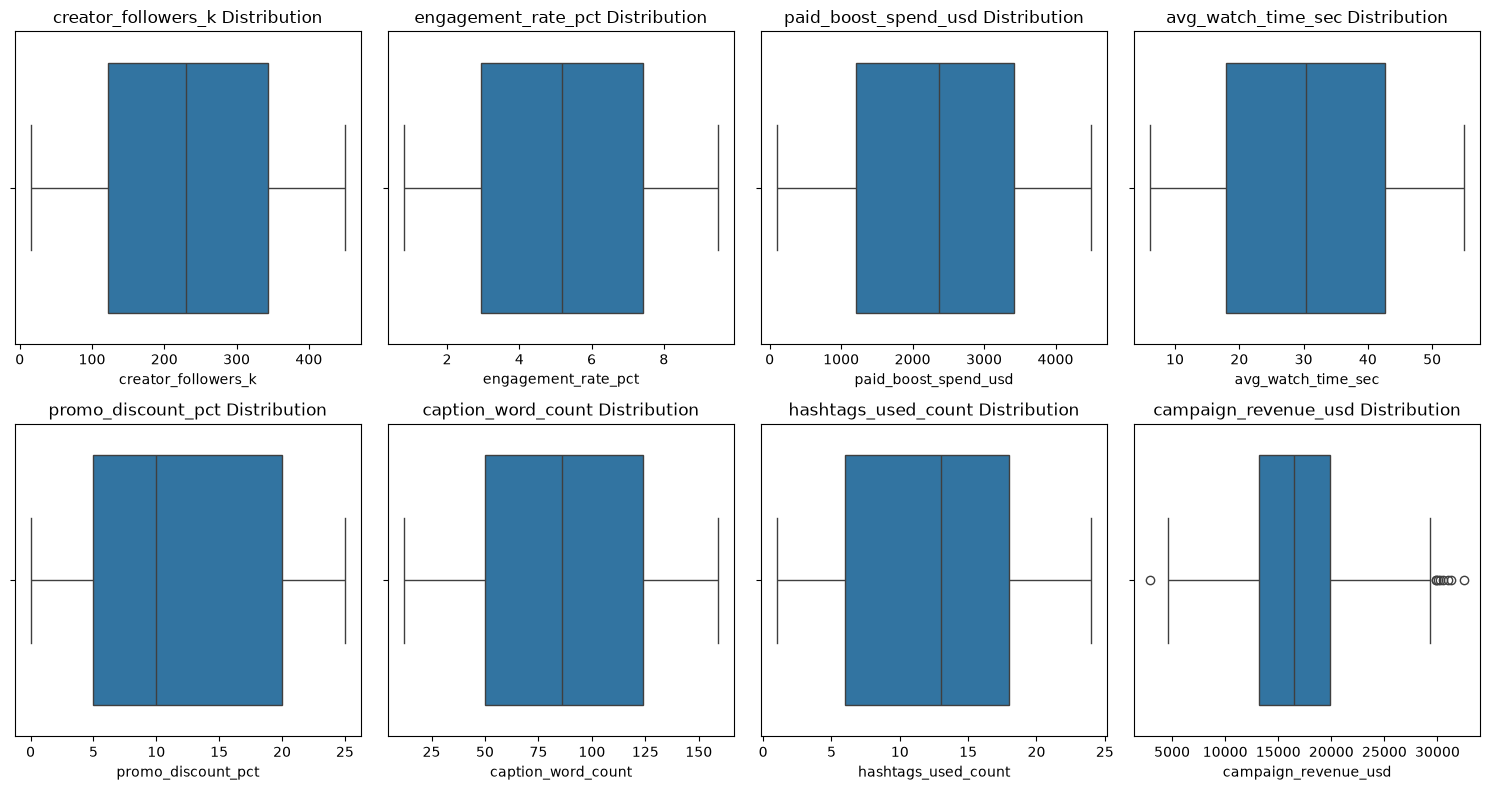

,mean,count
content_format,,
Short-Video-Reel,16633.0,1518
Static-Carousel,15051.0,734
YouTube-Deep-Dive,18369.0,748


,mean,count
audience_intent_tier,,
Broad-Entertainment,15200.0,1034
High-Intent-Niche,18472.0,751
Lifestyle-Warm,16828.0,1215


,mean,count
creator_phone_os,,
Android,16640.0,1530
iOS,16719.0,1470


,mean,count
contract_payment_terms,,
Net-15,16755.0,1024
Net-30,16516.0,998
Upfront,16765.0,978


,mean,count
posting_day_weather,,
Cloudy,16675.0,1018
Rainy,16852.0,957
Sunny,16520.0,1025


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
  sns.boxplot(data=inf_data, x=feature, ax=axes[i])
  axes[i].set_title(f'{feature} Distribution')

plt.tight_layout()
plt.show()

for feature in categorical_features:
    display(inf_data.groupby(feature)['campaign_revenue_usd'].agg(['mean', 'count']).round(0))

In [11]:
inf_data[numerical_features].skew()

creator_followers_k     0.024554
engagement_rate_pct    -0.020467
paid_boost_spend_usd   -0.048377
avg_watch_time_sec     -0.002695
promo_discount_pct      0.019796
caption_word_count     -0.015902
hashtags_used_count    -0.009567
campaign_revenue_usd    0.213697
dtype: float64

# Insights

*   Looking at the describe table, all numerical columns show little to no skewness which means values are largely symmetric.
*   Judging from the boxplots and outlier summary, there are no outliers in the numerical columns aside from the target revenue column `campaign_revenue_usd` which has 0.3% outliers which are negligible.
*   `audience_intent_tier` and `content_format` are meaningful drivers. High-Intent-Niche campaigns average about \$18.5k versus about \$15.2k for Broad-Entertainment, and YouTube-Deep-Dive averages about \$18.4k versus about \$15.1k for Static-Carousel.
*   There are no missing values in data.
*   There are no duplicates in data.

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,caption_word_count,hashtags_used_count,campaign_revenue_usd
creator_followers_k,1.000000,0.008232,-0.039713,-0.014288,0.000145,-0.027796,-0.004817,0.519312
engagement_rate_pct,0.008232,1.000000,0.015172,0.051056,0.012178,0.024897,-0.024634,0.536494
paid_boost_spend_usd,-0.039713,0.015172,1.000000,0.008782,0.000353,-0.014132,0.027906,0.456036
avg_watch_time_sec,-0.014288,0.051056,0.008782,1.000000,0.008975,0.011263,0.004782,0.198176
promo_discount_pct,0.000145,0.012178,0.000353,0.008975,1.000000,-0.003278,-0.016193,0.203321
caption_word_count,-0.027796,0.024897,-0.014132,0.011263,-0.003278,1.000000,0.021713,-0.010518
hashtags_used_count,-0.004817,-0.024634,0.027906,0.004782,-0.016193,0.021713,1.000000,0.006891
campaign_revenue_usd,0.519312,0.536494,0.456036,0.198176,0.203321,-0.010518,0.006891,1.000000


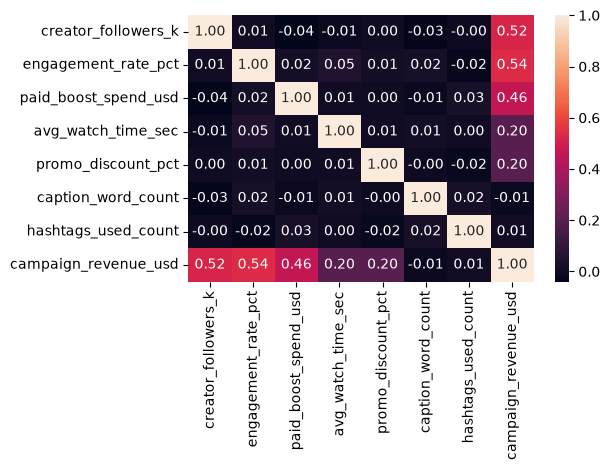

In [12]:
corr = inf_data[numerical_features].corr()

display(corr)

sns.heatmap(corr, annot=True, fmt='.2f')
plt.tight_layout()
plt.show()

### Relationship between features and revenue

**Strong-to-moderate positive relationships**
* `engagement_rate_pct` (0.54): higher engagement goes with higher revenue.
* `creator_followers_k` (0.52): revenue rises with audience size, about as strongly as engagement.
* `paid_boost_spend_usd` (0.46): more paid boosting is moderately associated with more revenue.

**Weak positive relationships**
* `avg_watch_time_sec` (0.20) and `promo_discount_pct` (0.20): small positive links.

**Essentially no relationship**
* `caption_word_count` and `hashtags_used_count` (about 0).

**Other findings**
* The scatter plots show roughly straight-line relationships, which supports starting with a linear model.
* The features are almost uncorrelated with each other (absolute correlation below 0.06), so there is no multicollinearity problem.
* Among categorical features, only `audience_intent_tier` and `content_format` show clear differences in average revenue. `creator_phone_os`, `contract_payment_terms` and `posting_day_weather` look almost identical across their levels.

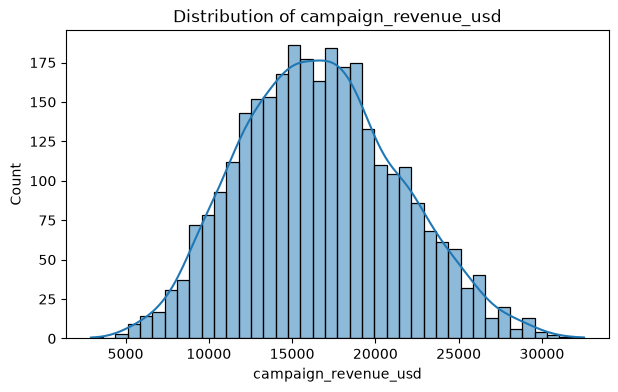

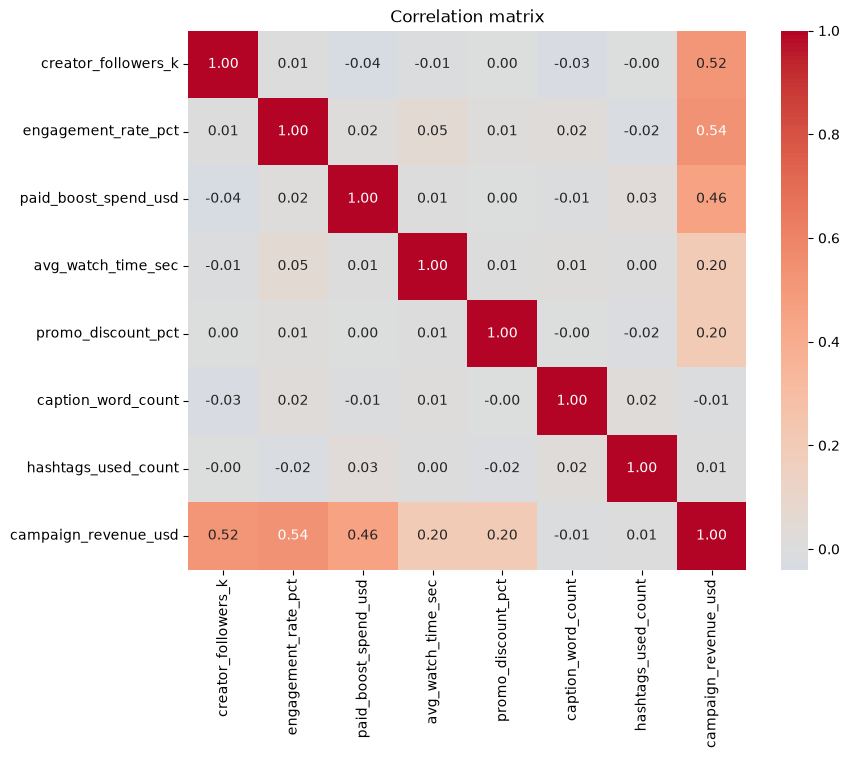

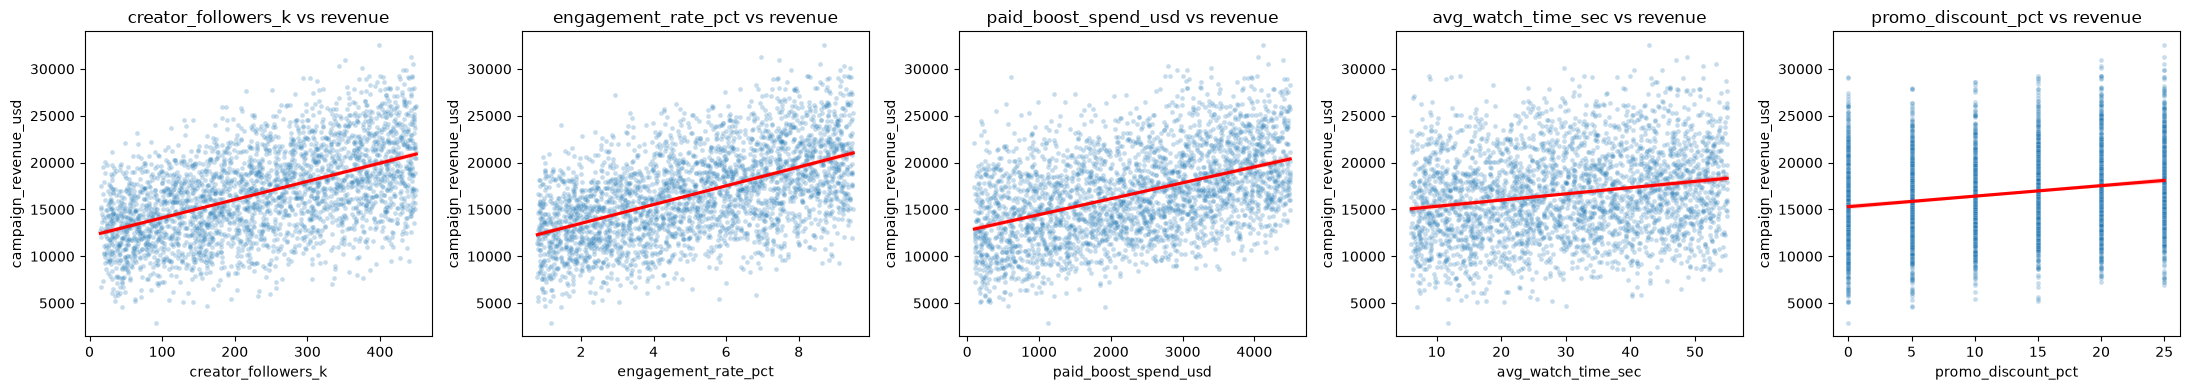

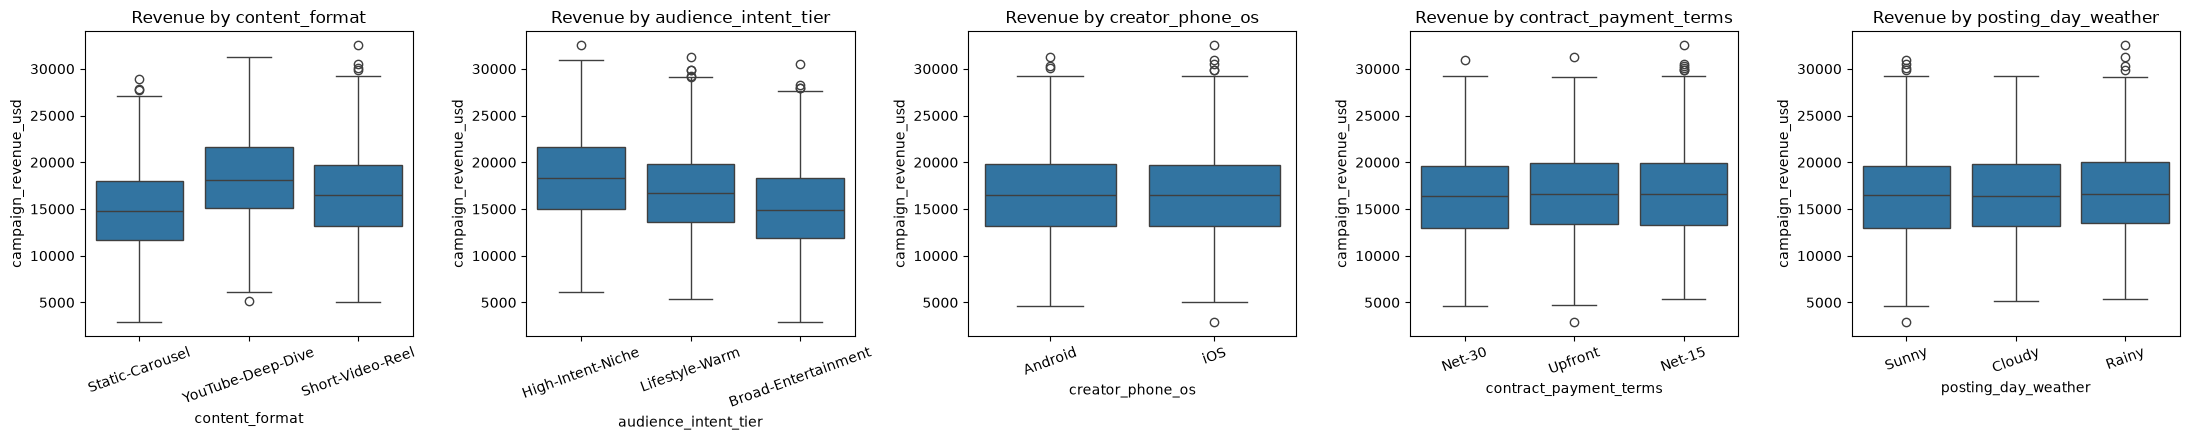

In [13]:
num_feats = [c for c in numerical_features if c != 'campaign_revenue_usd']

plt.figure(figsize=(7, 4))
sns.histplot(inf_data['campaign_revenue_usd'], bins=40, kde=True)
plt.title('Distribution of campaign_revenue_usd')
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(inf_data[num_feats + ['campaign_revenue_usd']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, f in zip(axes, ['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd',
                        'avg_watch_time_sec', 'promo_discount_pct']):
    sns.scatterplot(data=inf_data, x=f, y='campaign_revenue_usd', alpha=0.25, s=12, ax=ax)
    sns.regplot(data=inf_data, x=f, y='campaign_revenue_usd', scatter=False, color='red', ax=ax)
    ax.set_title(f'{f} vs revenue')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, f in zip(axes, categorical_features):
    sns.boxplot(data=inf_data, x=f, y='campaign_revenue_usd', ax=ax)
    ax.set_title(f'Revenue by {f}')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

In [14]:
rows_before = len(inf_data)
inf_data.drop_duplicates(inplace=True)
inf_data.dropna(inplace=True)
inf_data.reset_index(drop=True, inplace=True)
print(f'Rows before: {rows_before}, after: {len(inf_data)}')

Q1, Q3 = inf_data['campaign_revenue_usd'].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = inf_data[(inf_data['campaign_revenue_usd'] < Q1 - 1.5 * IQR) | (inf_data['campaign_revenue_usd'] > Q3 + 1.5 * IQR)]
display(outliers[['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd', 'campaign_revenue_usd']].sort_values('campaign_revenue_usd'))

Rows before: 3000, after: 3000


,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,campaign_revenue_usd
1325,91.2,1.17,1119.0,2915.63
120,432.1,9.14,3060.0,29865.42
1240,435.7,7.79,2923.0,29905.14
1402,375.1,9.42,3400.0,30047.18
2741,344.0,9.25,2795.0,30265.73
2536,445.3,8.59,4192.0,30485.23
1172,351.6,7.45,4397.0,30959.26
2027,443.3,6.96,4044.0,31309.34
2635,398.2,8.69,4115.0,32527.89


### Outlier treatment decision
* **Features:** the IQR check found no outliers in any feature, so nothing needs capping or removal.
* **Target:** 9 of 3,000 campaigns (0.3%) fall outside the IQR fences. I **kept** them. The table above shows the high-revenue ones belong to creators with large audiences, so the revenue is explained by the features and is not a data error. Removing real high performers would bias the model toward average campaigns, and 0.3% of rows has a negligible effect on the fit.
* Differences in feature scale are handled by `StandardScaler` inside the pipeline.

In [15]:
numerical_features = [c for c in numerical_features if c != 'campaign_revenue_usd']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

In [16]:
X = inf_data.drop(columns=['campaign_revenue_usd'])
y = inf_data['campaign_revenue_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

**Train/test split:** 70% (2,100 campaigns) is used for training and cross-validation, and 30% (900) is held out and used once at the end. The target is continuous, so the split is random with a fixed seed (42).

In [17]:
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
pred = baseline.predict(X_test)
print('RMSE:', np.sqrt(mean_squared_error(y_test, pred)),
        '| MAE:', mean_absolute_error(y_test, pred), '| R2:', r2_score(y_test, pred))

RMSE: 4830.787653250551 | MAE: 3901.0275076190474 | R2: -0.000962386229961254


**Reading the baseline:** predicting the average revenue for every campaign gives R² of about 0 and an RMSE of roughly $4,800. This is the floor that any useful model must beat.

### Model Selection Reasoning

I used the Supervised Learning Model Selection Guideline to choose the candidate models.

* **Dataset size:** 3,000 campaigns, so the **small dataset** branch (under 5,000 rows).
* **Is the relationship mostly linear?** Yes. Revenue rises steadily with engagement (r = 0.54), followers (0.52) and boost spend (0.46), and the features are almost uncorrelated with each other. The guideline says to start with simple, interpretable models and avoid complex ones that overfit.
* **Are outliers important?** No. None of the features has outliers, and only 0.3% of the target does, so the "standard models can work well" box applies: Linear Regression, Decision Tree, KNN and SVM.
* **Additional considerations:** marketing needs to know which levers drive revenue (interpretability) and wants fast what-if forecasts (speed). Both favour Linear Regression. The metric is RMSE, with MAE and R², as the guideline's final step recommends.

**Chosen models:**
1. **Linear Regression** (Linear and Regularized family): the first choice for a mostly linear problem. It is fast and its coefficients give the dollar effect of each lever. `SelectFpr` feature selection keeps it simple and plays the role that Lasso or Ridge would.
2. **Random Forest** (Tree-Based family): captures non-linear effects and interactions and is robust to outliers. It checks whether the linear assumption leaves signal on the table.
3. **K-Nearest Neighbours** (Instance-Based family): listed for small datasets. It predicts from the most similar past campaigns and assumes no functional form.

In [18]:
pipeline_lr = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
                               ('regressor', LinearRegression())])

param_grid_lr = {
    'feature_selection__alpha': [0.01, 0.05, 0.1],
    'regressor__fit_intercept': [True, False],
}

grid_search_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search_lr.fit(X_train, y_train)

print(f"Best parameters for Linear Regression: {grid_search_lr.best_params_}")
print(f"Best RMSE for Linear Regression: {np.sqrt(-grid_search_lr.best_score_):.2f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters for Linear Regression: {'feature_selection__alpha': 0.05, 'regressor__fit_intercept': True}
Best RMSE for Linear Regression: 774.51


In [19]:
pipeline_rf = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
                               ('regressor', RandomForestRegressor(random_state=42))])

param_grid_rf = {
    'regressor__n_estimators': [200, 500],
    'regressor__max_depth': [None, 10, 20],
    'regressor__min_samples_leaf': [1, 5, 10],
    'regressor__max_features': ['sqrt', 1.0],
}

grid_search_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search_rf.fit(X_train, y_train)

print(f"Best parameters for Random Forest: {grid_search_rf.best_params_}")
print(f"Best RMSE for Random Forest: {np.sqrt(-grid_search_rf.best_score_):.2f}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters for Random Forest: {'regressor__max_depth': None, 'regressor__max_features': 'sqrt', 'regressor__min_samples_leaf': 1, 'regressor__n_estimators': 500}
Best RMSE for Random Forest: 1319.55


In [20]:
pipeline_knn = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
                               ('regressor', KNeighborsRegressor())])

param_grid_knn = {
    'regressor__n_neighbors': [3, 5, 10, 20],
    'regressor__weights': ['uniform', 'distance'],
    'regressor__p': [1, 2],
}

grid_search_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search_knn.fit(X_train, y_train)

print(f"Best parameters for K Nearest Neighbors: {grid_search_knn.best_params_}")
print(f"Best RMSE for K Nearest Neighbors: {np.sqrt(-grid_search_knn.best_score_):.2f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits


Best parameters for K Nearest Neighbors: {'regressor__n_neighbors': 10, 'regressor__p': 2, 'regressor__weights': 'distance'}
Best RMSE for K Nearest Neighbors: 1270.09


In [21]:
best_models = {
    'LinearRegression': {'model': grid_search_lr.best_estimator_, 'rmse': np.sqrt(-grid_search_lr.best_score_)},
    'RandomForest': {'model': grid_search_rf.best_estimator_, 'rmse': np.sqrt(-grid_search_rf.best_score_)},
    'KNearestNeighbors': {'model': grid_search_knn.best_estimator_, 'rmse': np.sqrt(-grid_search_knn.best_score_)}
}

best_model_name = min(best_models, key=lambda k: best_models[k]['rmse'])
best_model_info = best_models[best_model_name]

print(f"The best model is {best_model_name} with an RMSE of {best_model_info['rmse']:.2f}")

The best model is LinearRegression with an RMSE of 774.51


In [22]:
results = []
for name, info in best_models.items():
    y_pred = info['model'].predict(X_test)
    results.append({
        'model': name,
        'cv_rmse': info['rmse'],
        'test_rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
        'test_mae': mean_absolute_error(y_test, y_pred),
        'test_r2': r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index('model').round(3)
display(results_df)

,cv_rmse,test_rmse,test_mae,test_r2
model,,,,
LinearRegression,774.506,799.462,630.994,0.973
RandomForest,1319.549,1289.109,1019.547,0.929
KNearestNeighbors,1270.089,1250.381,966.718,0.933


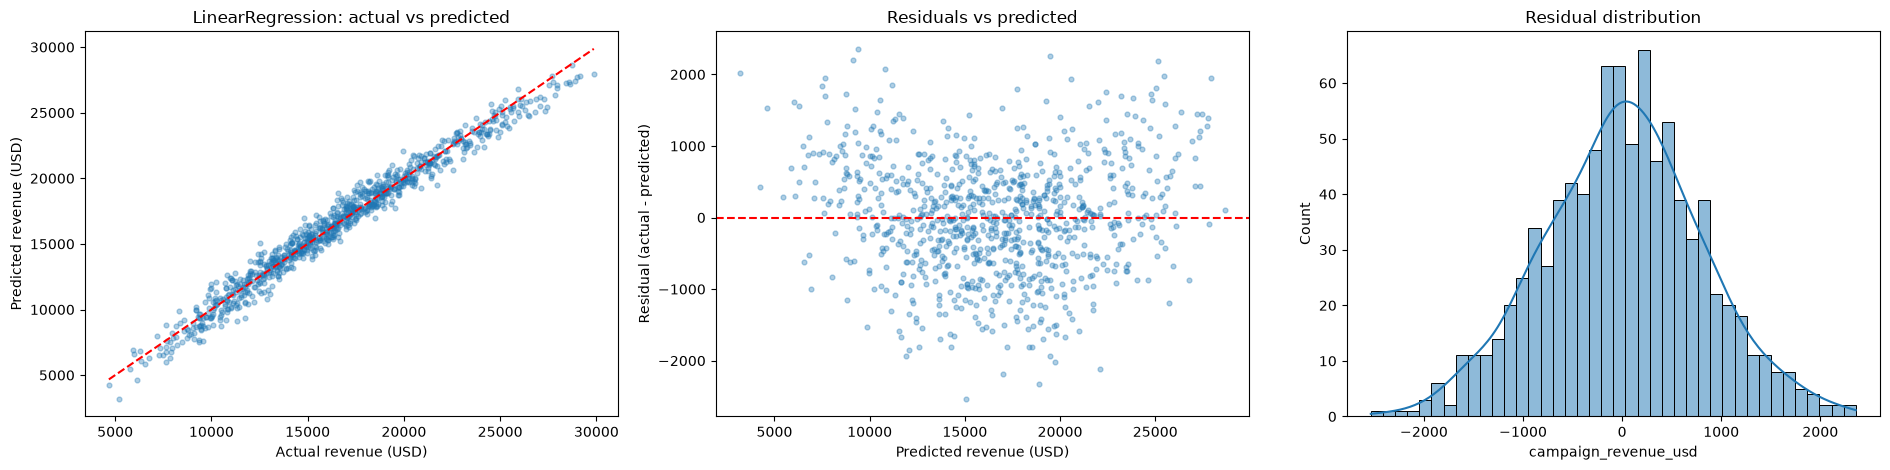

Residual mean: 6.4 | std: 799.9


In [23]:
best_pred = best_model_info['model'].predict(X_test)
residuals = y_test - best_pred

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

axes[0].scatter(y_test, best_pred, alpha=0.35, s=12)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('Actual revenue (USD)'); axes[0].set_ylabel('Predicted revenue (USD)')
axes[0].set_title(f'{best_model_name}: actual vs predicted')

axes[1].scatter(best_pred, residuals, alpha=0.35, s=12)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted revenue (USD)'); axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residuals vs predicted')

sns.histplot(residuals, bins=40, kde=True, ax=axes[2])
axes[2].set_title('Residual distribution')

plt.tight_layout()
plt.show()
print(f'Residual mean: {residuals.mean():.1f} | std: {residuals.std():.1f}')

In [24]:
joblib.dump(best_model_info['model'], 'influencer_revenue_model.pkl')

['influencer_revenue_model.pkl']

## Conclusion

* **Problem:** forecast the 14-day trackable revenue of an influencer campaign and identify the levers that drive it.
* **Data:** 3,000 campaigns and 12 features, with no missing values or duplicates. Features are symmetric and almost independent of each other. Only the target had outliers (0.3%), and I kept them because they belong to large-audience creators and are explained by the features.
* **Final model:** Linear Regression. It is the most accurate (errors about 35% to 40% lower than the other two), generalises well (CV and test results agree) and is the easiest to explain. Random Forest and KNN are less accurate because the data behave like an additive linear signal plus noise, which flexible models need much more data to match.